# Notebook 3 – Data Quality Assessment

Goal: **identify and document** problems. No cleaning is performed in this sprint.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet).
# This loader checks common local locations first, then tries the public source.
from pathlib import Path

TELCO_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/main/data/Telco-Customer-Churn.csv",
]

candidate_names = [
    "telco.csv",
    "Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

search_roots = [Path.cwd(), *list(Path.cwd().parents)[:4]]
local_candidates = []
for root in search_roots:
    for name in candidate_names:
        local_candidates.extend([
            root / name,
            root / "data" / name,
            root / "Datasets" / name,
            root / "dataset" / name,
        ])

local_path = next((p.resolve() for p in local_candidates if p.is_file()), None)

if local_path is not None:
    df_raw = pd.read_csv(local_path)
    print("Loaded local dataset:", local_path)
else:
    load_errors = []
    df_raw = None
    for url in TELCO_URLS:
        try:
            df_raw = pd.read_csv(url)
            print("Loaded dataset from public source.")
            break
        except Exception as exc:
            load_errors.append(f"{url} -> {type(exc).__name__}: {exc}")
    if df_raw is None:
        raise FileNotFoundError(
            "Could not find the Telco dataset locally, and downloading it failed. "
            "Place the original Telco Customer Churn CSV in a 'data' folder next to "
            "your notebooks (or in the parent folder's 'data' folder), name it "
            "'telco.csv' or 'Telco-Customer-Churn.csv', and rerun this cell. "
            "If using a URL, check your internet connection.\n\nDetails:\n"
            + "\n".join(load_errors)
        )

df = df_raw.copy()
print("Loaded:", df.shape)


Loaded: (7043, 21)


### Topic Explanation

This topic finds absent values and quantifies how much data is missing in each field.

## 1. Missing Values

### 1. Concept
Missing values are cells with no recorded value (`NaN`/`None`). Measure: **count**, **percentage**, **by column**, and **pattern** (are they random, or linked to other columns?). Hidden missing values (blank strings, placeholders) will not be found by `isnull()` alone.

### 2. Example
*Simple:* an unanswered question on a form.  
*Business:* a customer with no total bill recorded.  
*AI/ML use:* most algorithms cannot accept NaN; the *reason* for missingness decides the treatment (drop, impute, flag).

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [2]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(2),
})
display(missing[missing.missing_count > 0] if missing.missing_count.sum() else missing.head())
print("Total missing cells detected by isnull():", int(df.isnull().sum().sum()))

,missing_count,missing_pct
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0


Total missing cells detected by isnull(): 0


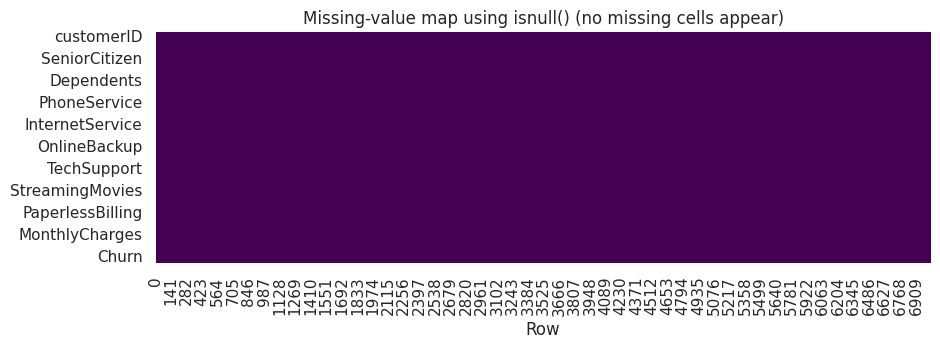

In [3]:
# visual pattern check: a heatmap of the null mask (white = missing)
plt.figure(figsize=(10, 3))
sns.heatmap(df.isnull().T, cbar=False, cmap="viridis")
plt.title("Missing-value map using isnull() (no missing cells appear)")
plt.xlabel("Row"); plt.show()

### 5. Interpretation
`isnull()` reports **0 missing cells** in all 21 columns. That looks perfect, but it only counts true `NaN`. The `TotalCharges` text column is checked for hidden blanks in the next section.

### 6. Insight
A clean `isnull()` report is not proof of completeness. Always look for placeholder values.

### 7. AI/ML Relevance
If hidden blanks are not converted to NaN, `to_numeric` fails or imputers do not see them, and the pipeline crashes or silently learns wrong values.

### Topic Explanation

This topic checks for blank strings and other missing-value representations that ordinary null checks may not catch.

## 2. Null-like Values and Empty Strings

### 1. Concept
Null-like values are placeholders that *mean* missing but are not NaN: `""`, `" "`, `"NA"`, `"N/A"`, `"null"`, `"None"`, `"?"`, `"-"`, `"unknown"`, `"missing"`.

### 2. Example
*Simple:* writing 'none' or leaving a blank on a form.  
*Business:* a billing system exports blank totals for customers who have not been billed yet.  
*AI/ML use:* hidden nulls make numeric columns load as text (as happens here).

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [4]:
null_like = {"", "na", "n/a", "nan", "null", "none", "?", "-", "--", "unknown", "missing", "undefined"}

rows = []
for c in df.select_dtypes(exclude="number").columns:
    s = df[c].astype(str).str.strip().str.lower()
    cnt = int(s.isin(null_like).sum())
    if cnt:
        rows.append((c, cnt))
print("Columns with null-like / empty values:")
display(pd.DataFrame(rows, columns=["column", "count"]))

blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges rows:", int(blank_mask.sum()))
display(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

Columns with null-like / empty values:


,column,count
0,TotalCharges,11


Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [5]:
# why is TotalCharges text? find values that cannot be parsed as numbers
converted = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad = df.loc[converted.isna(), "TotalCharges"]
print("Unparseable values:", bad.map(repr).unique())
print("Missing after conversion:", converted.isna().sum(), f"({converted.isna().mean()*100:.2f}%)")

Unparseable values: <StringArray>
['' '']
Length: 1, dtype: str
Missing after conversion: 11 (0.16%)


### 5. Interpretation
There are **11 rows where `TotalCharges` is a blank string** (`' '`). They are the only reason the whole column is text. All 11 have `tenure = 0`, i.e. brand-new customers who have not yet been billed; none of them churned, and they are on one- or two-year contracts.

### 6. Insight
This is *not random* missingness: it is structurally explained by `tenure = 0` (no billing cycle completed). A reasonable treatment later would be to set `TotalCharges = 0` (or `MonthlyCharges × tenure`) – not mean-imputation. The affected share is only 0.16% of rows.

### 7. AI/ML Relevance
Knowing the mechanism (structural, not random) lets us choose a logically correct imputation and avoids inventing values.

### Topic Explanation

This topic examines where missing values occur across records and columns to identify possible patterns.

## 3. Missing Value Patterns

### 1. Concept
Pattern analysis checks whether missingness depends on other variables (MCAR, MAR, MNAR). Compare the characteristics of rows with and without the missing value.

### 2. Example
*Simple:* only people under 18 skip the 'salary' question – missing depends on age.  
*Business:* blanks occur only for just-signed customers.  
*AI/ML use:* a missing-indicator can itself be a useful feature when missingness is informative.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [6]:
tmp = df.copy()
tmp["TotalCharges_missing"] = tmp["TotalCharges"].astype(str).str.strip().eq("")
display(tmp.groupby("TotalCharges_missing")[["tenure", "MonthlyCharges"]].agg(["min", "mean", "max"]))
print("Tenure values among missing rows:", tmp.loc[tmp.TotalCharges_missing, "tenure"].unique())
print("Customers with tenure == 0 overall:", (tmp.tenure == 0).sum())

tenure                MonthlyCharges                   
                        min       mean max            min       mean     max
TotalCharges_missing                                                        
False                     1  32.421786  72          18.25  64.798208  118.75
True                      0   0.000000   0          19.70  41.418182   80.85

Tenure values among missing rows: [0]
Customers with tenure == 0 overall: 11


### 5. Interpretation
All rows with a missing `TotalCharges` have `tenure = 0`, and *every* `tenure = 0` customer is missing `TotalCharges` (11 of 11). The pattern is deterministic.

### 6. Insight
Missingness is fully explained by another column, so the best imputation is rule-based (0), not statistical.

### 7. AI/ML Relevance
Pattern-based reasoning gives better imputation and prevents bias compared with generic mean/median fills.

### Topic Explanation

This topic identifies repeated records and helps distinguish exact duplicates from records that only look similar.

## 4. Duplicate Records

### 1. Concept
**Exact duplicates** have identical values in all columns. **Potential duplicates** share the same key attributes (e.g. same customer ID, or identical feature values except for the ID).

### 2. Example
*Simple:* the same form submitted twice.  
*Business:* duplicate customers inflate revenue and customer counts.  
*AI/ML use:* duplicates can leak between train and test sets and overweight some patterns.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [7]:
print("Completely duplicated rows            :", df.duplicated().sum())
print("Duplicated customerID                 :", df["customerID"].duplicated().sum())

feature_cols = [c for c in df.columns if c != "customerID"]
dup_mask = df.duplicated(subset=feature_cols, keep=False)
print("Rows identical in all columns except ID:", int(dup_mask.sum()),
      f"({df.duplicated(subset=feature_cols).sum()} extra copies)")

Completely duplicated rows            : 0
Duplicated customerID                 : 0
Rows identical in all columns except ID: 42 (22 extra copies)


In [8]:
# inspect a few potential duplicates
pot = df[dup_mask].sort_values(feature_cols)
display(pot.head(8))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6491,9728-FTTVZ,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
6764,7660-HDPJV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
4495,4702-IOQDC,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
6267,0328-GRPMV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
5522,2619-WFQWU,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes
5759,9985-MWVIX,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes
542,2866-IKBTM,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,8605-ITULD,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No


### 5. Interpretation
There are **no complete duplicates** and **no repeated `customerID`s**. However 22 rows are copies of another row when the ID is ignored (42 rows involved).

### 6. Insight
Different IDs mean they are distinct customers who happen to have identical plans and charges (typical for a small-tenure, standard-plan group). They should be **retained**, but the near-duplicates are worth noting because they can cause mild leakage across train/test splits.

### 7. AI/ML Relevance
Always decide duplicates by business logic: dropping valid customers would bias the data, keeping real duplicates would leak.

### Topic Explanation

This topic checks whether values violate valid ranges, rules, or expected categories.

## 5. Invalid Values: Negatives, Impossible Values, Unexpected Values

### 1. Concept
Domain rules define what is valid: counts and money should be non-negative, tenure should be within company age, flags should have only expected labels.

### 2. Example
*Simple:* an age of –5 or 250.  
*Business:* a negative monthly bill or a 'Fibre' typo in a category.  
*AI/ML use:* invalid values distort statistics and create false outliers or phantom categories.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [9]:
num = df.copy()
num["TotalCharges"] = pd.to_numeric(num["TotalCharges"], errors="coerce")

checks = {
    "tenure < 0": (num.tenure < 0).sum(),
    "tenure > 72 (max plausible per data)": (num.tenure > 72).sum(),
    "tenure == 0": (num.tenure == 0).sum(),
    "MonthlyCharges <= 0": (num.MonthlyCharges <= 0).sum(),
    "TotalCharges < 0": (num.TotalCharges < 0).sum(),
    "TotalCharges < MonthlyCharges (and tenure>=1)": ((num.TotalCharges < num.MonthlyCharges) & (num.tenure >= 1)).sum(),
    "SeniorCitizen not in {0,1}": (~num.SeniorCitizen.isin([0, 1])).sum(),
}
pd.Series(checks, name="violations").to_frame()

,violations
tenure < 0,0
tenure > 72 (max plausible per data),0
tenure == 0,11
MonthlyCharges <= 0,0
TotalCharges < 0,0
TotalCharges < MonthlyCharges (and tenure>=1),0
"SeniorCitizen not in {0,1}",0


In [10]:
# consistency between TotalCharges and tenure * MonthlyCharges
exp = num.tenure * num.MonthlyCharges
diff = (num.TotalCharges - exp)
rel = (diff / exp.replace(0, np.nan)).abs()
print(diff.describe().round(2))
print("Rows where |relative difference| > 50%:", int((rel > 0.5).sum()))
display(num.loc[rel > 0.5, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]].head())

count    7032.00
mean        0.15
std        67.26
min      -370.85
25%       -28.65
50%         0.00
75%        28.70
max       373.25
dtype: float64
Rows where |relative difference| > 50%: 2


,customerID,tenure,MonthlyCharges,TotalCharges
869,0323-XWWTN,3,26.4,121.25
5595,2308-STERM,2,19.4,61.05


### 5. Interpretation
No negative values and no impossible `tenure`/charges. The only boundary case is `tenure = 0` (11 rows). `TotalCharges` is on average close to `tenure × MonthlyCharges` but differs for many customers (price changes, discounts, plan upgrades over time) – this is normal, not an error.

### 6. Insight
Numerical validity is good. The few rows with large relative deviations should be understood as customers whose plan changed, not as data errors.

### 7. AI/ML Relevance
Range/logic checks give confidence that numeric columns can be modelled; they also provide candidate features (e.g. average spend per month = `TotalCharges/tenure`).

### Topic Explanation

This topic detects inconsistent category spelling, spacing, and labels that can split one category into multiple values.

## 6. Incorrect Categories, Unexpected Labels and Whitespace

### 1. Concept
Categorical columns should contain a small, consistent set of labels. Problems: typos, inconsistent case, trailing spaces, redundant levels that duplicate another column's information.

### 2. Example
*Simple:* 'Male', 'male', 'M' for the same thing.  
*Business:* 'No internet service' in streaming columns repeats the information already in `InternetService = No`.  
*AI/ML use:* spurious categories inflate one-hot dimensionality and weaken estimates.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [11]:
cat = df.select_dtypes(exclude="number").drop(columns=["customerID", "TotalCharges"])
for c in cat.columns:
    vals = sorted(cat[c].unique())
    print(f"{c:<18} {len(vals)} -> {vals}")

gender             2 -> ['Female', 'Male']
Partner            2 -> ['No', 'Yes']
Dependents         2 -> ['No', 'Yes']
PhoneService       2 -> ['No', 'Yes']
MultipleLines      3 -> ['No', 'No phone service', 'Yes']
InternetService    3 -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity     3 -> ['No', 'No internet service', 'Yes']
OnlineBackup       3 -> ['No', 'No internet service', 'Yes']
DeviceProtection   3 -> ['No', 'No internet service', 'Yes']
TechSupport        3 -> ['No', 'No internet service', 'Yes']
StreamingTV        3 -> ['No', 'No internet service', 'Yes']
StreamingMovies    3 -> ['No', 'No internet service', 'Yes']
Contract           3 -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   2 -> ['No', 'Yes']
PaymentMethod      4 -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              2 -> ['No', 'Yes']


In [12]:
# whitespace / case variants
issues = {}
for c in cat.columns:
    s = cat[c]
    stripped = s.str.strip()
    if (s != stripped).any():
        issues[c] = "leading/trailing whitespace"
    if stripped.str.lower().nunique() != stripped.nunique():
        issues[c] = issues.get(c, "") + " case variants"
print("Whitespace/case issues:", issues if issues else "none found")

# redundant levels
print("\nRedundant 'No internet service' levels:")
print(df.loc[df.InternetService == "No", ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]].nunique())
print("\nMultipleLines vs PhoneService:")
display(pd.crosstab(df.PhoneService, df.MultipleLines))

Whitespace/case issues: none found

Redundant 'No internet service' levels:
OnlineSecurity      1
OnlineBackup        1
DeviceProtection    1
TechSupport         1
StreamingTV         1
StreamingMovies     1
dtype: int64

MultipleLines vs PhoneService:


MultipleLines,No,No phone service,Yes
PhoneService,,,
No,0,682,0
Yes,3390,0,2971


### 5. Interpretation
All categorical columns have clean, consistent labels (no typos, case or whitespace problems). Two structural redundancies exist: six add-on columns carry `No internet service` for the 1,526 customers without internet, and `MultipleLines` carries `No phone service` for the 682 customers without phone.

### 6. Insight
These levels are logically valid but redundant – they duplicate `InternetService == 'No'` / `PhoneService == 'No'`. In preprocessing they can be merged with `No` (or kept as a dependency flag).

### 7. AI/ML Relevance
Redundant levels create perfectly correlated dummy variables, which causes multicollinearity in linear models.

### Topic Explanation

This topic checks each column's stored data type and non-null count so data can be interpreted correctly.

## 7. Incorrect Data Types and Invalid Dates

### 1. Concept
Each column should be stored in the type that matches its meaning. Dates must parse and fall in a valid range.

### 2. Example
*Simple:* a phone number stored as a float loses leading zeros.  
*Business:* a numeric money column stored as text cannot be summed.  
*AI/ML use:* wrong types break scalers and encoders.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [13]:
type_report = pd.DataFrame({
    "current_dtype": df.dtypes.astype(str),
    "should_be": ["identifier(str)", "category", "category (binary flag)", "category", "category", "integer (numeric)",
                  "category", "category", "category", "category", "category", "category", "category", "category",
                  "category", "category", "category", "category", "float", "float", "category (target)"],
})
type_report["mismatch"] = [
    (a == "str" or a == "object") and "float" in b or (a.startswith("int") and "category" in b)
    for a, b in zip(type_report.current_dtype, type_report.should_be)
]
display(type_report[type_report.mismatch])

print("Date/time columns in this dataset: none -> invalid-date checks not applicable.")
print("Demo of how an invalid date would be detected:")
demo = pd.Series(["2024-02-30", "2024-03-15", "15/13/2024"])
print(pd.to_datetime(demo, errors="coerce"))

,current_dtype,should_be,mismatch
SeniorCitizen,int64,category (binary flag),True
TotalCharges,str,float,True


Date/time columns in this dataset: none -> invalid-date checks not applicable.
Demo of how an invalid date would be detected:
0          NaT
1   2024-03-15
2          NaT
dtype: datetime64[us]


### 5. Interpretation
Two real type problems: `TotalCharges` (text → float) and `SeniorCitizen` (int → categorical flag). No date columns exist; the demo shows how `errors='coerce'` surfaces invalid dates as `NaT`.

### 6. Insight
Type fixing is a trivial but critical step; forgetting it for `TotalCharges` would drop a very important numeric feature.

### 7. AI/ML Relevance
Correct dtypes allow the right preprocessing pipeline (`ColumnTransformer`: numeric → scaler, categorical → encoder).

### Topic Explanation

This topic consolidates the notebook's findings into a concise summary for review and communication.

## 8. Data Quality Summary Table

### 1. Concept
A one-page register of every issue found, its severity and its proposed handling in the next sprint.

### 2. Example
Like a defect log in software testing.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [14]:
issues = pd.DataFrame([
    ["TotalCharges stored as text", "Data type", "Column-wide", "High", "Convert to float"],
    ["Blank strings in TotalCharges", "Hidden missing", "11 rows (0.16%)", "High", "Set to 0 (tenure = 0, structural)"],
    ["SeniorCitizen is 0/1 int", "Data type", "Column-wide", "Low", "Treat as categorical flag"],
    ["'No internet service' levels", "Redundant category", "6 columns / 1,526 rows", "Medium", "Merge with 'No' or keep as flag"],
    ["'No phone service' level", "Redundant category", "1 column / 682 rows", "Low", "Merge with 'No'"],
    ["Identical rows ignoring ID", "Potential duplicates", "22 extra rows", "Low", "Keep; watch for split leakage"],
    ["customerID", "Identifier", "Column-wide", "Medium", "Drop before modelling"],
    ["Churn class imbalance", "Target quality", "26.5% positives", "Medium", "Stratified split, class weights"],
], columns=["Issue", "Type", "Scope", "Severity", "Proposed handling (next sprint)"])
issues

,Issue,Type,Scope,Severity,Proposed handling (next sprint)
0,TotalCharges stored as text,Data type,Column-wide,High,Convert to float
1,Blank strings in TotalCharges,Hidden missing,11 rows (0.16%),High,"Set to 0 (tenure = 0, structural)"
2,SeniorCitizen is 0/1 int,Data type,Column-wide,Low,Treat as categorical flag
3,'No internet service' levels,Redundant category,"6 columns / 1,526 rows",Medium,Merge with 'No' or keep as flag
4,'No phone service' level,Redundant category,1 column / 682 rows,Low,Merge with 'No'
5,Identical rows ignoring ID,Potential duplicates,22 extra rows,Low,Keep; watch for split leakage
6,customerID,Identifier,Column-wide,Medium,Drop before modelling
7,Churn class imbalance,Target quality,26.5% positives,Medium,"Stratified split, class weights"


### 5. Interpretation
A compact list of 8 items. Only 2 are *severe* and both concern `TotalCharges`.

### 6. Insight
Overall data quality is **good**: no true missing values, no impossible numbers, no duplicates; problems are mostly type/representation issues.

### 7. AI/ML Relevance
This register is the input to the data-cleaning sprint and demonstrates the engineer can find *hidden* issues, not only the obvious ones.